# Análisis Bivariante y Multivariante

##1. Análisis Bivariante

Entre dos variables. Ya sean numéricas (1,2,3,4) o categóricas (género, raza...). Las técnicas según lo que nos pidan o lo que vayamos a hacer.

In [4]:
#Importar librerías
import pandas as pd #DataFrames
import numpy as np #Numpy para estadísticas
import matplotlib.pyplot as plt #Plot: Histograma,pie
import seaborn as sns #Heatmap



#Configuraciónde estilo para los gráficos
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

#Creamos un dataset artificial
np.random.seed(42)
n_samples=200

data={
    'Horas_Estudio':np.random.normal(12,4,n_samples).clip(0,24),
    'Calificacion':[],
    'Asistencia': np.random.choice(['Alta','Media','Baja'],size=n_samples,p=[0.6,0.3,0.1]),
    'Tipo_Colegio':np.random.choice(['Privado','Pública'],size=n_samples,p=[0.6,0.4])
}

#Generamos las calificaciones según las horas de estudio
for horas in data['Horas_Estudio']:
  calif=30+(horas*2.5)+np.random.normal(0,8)
  data['Calificacion'].append(np.clip(calif,0,100))


df=pd.DataFrame(data)
df.head()



,Horas_Estudio,Calificacion,Asistencia,Tipo_Colegio
0,13.986857,59.762001,Media,Pública
1,11.446943,54.720354,Media,Privado
2,14.590754,61.737734,Media,Privado
3,18.092119,68.318372,Media,Pública
4,11.063387,58.046639,Alta,Privado


# Caso A: Numérica vs Numérica (Dispersión y Correlación)

Para analizar la relación entre las dos variables continuas (Horas de Estudio y Calificación), utilizamos el Gráfico de Dispersión y calculamos el coeficiente de correlación de Pearson.

<function matplotlib.pyplot.show(close=None, block=None)>

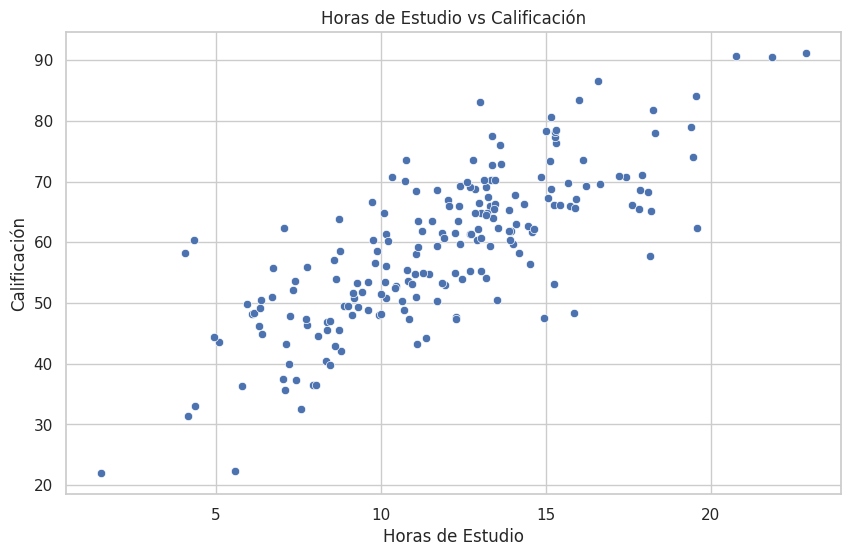

In [5]:
#1. Gráfico de Dispersión
sns.scatterplot(data=df,x='Horas_Estudio',y='Calificacion')
plt.title('Horas de Estudio vs Calificación')
plt.xlabel('Horas de Estudio')
plt.ylabel('Calificación')
plt.show

In [7]:
#2. Cálculo de correlación lineal de Pearson
correlacion=df['Horas_Estudio'].corr(df['Calificacion'])
print(f'Correlación: {correlacion}')
print(f'Correlación: {correlacion:.2f}')


Correlación: 0.7721418332926816
Correlación: 0.77


# Caso B: Categórica vs Numérica

Vamos a ver cómo varía la variable cuantitativa de Calficación según la Asistencia. Utilizaremos Diagramas de Caja o Diagramas de Violín.

<function matplotlib.pyplot.show(close=None, block=None)>

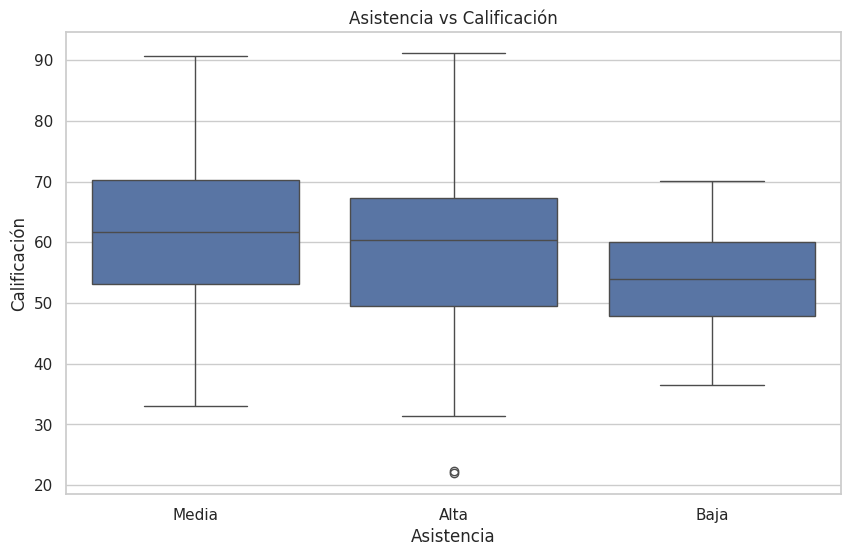

In [8]:
#Boxplot
sns.boxplot(data=df,x='Asistencia',y='Calificacion')
plt.title('Asistencia vs Calificación')
plt.xlabel('Asistencia')
plt.ylabel('Calificación')
plt.show

# 2. Análisis Multivariante

Agregar el tipo de colegio para ver cómo varía la correlación según el tipo de colegio.

<function matplotlib.pyplot.show(close=None, block=None)>

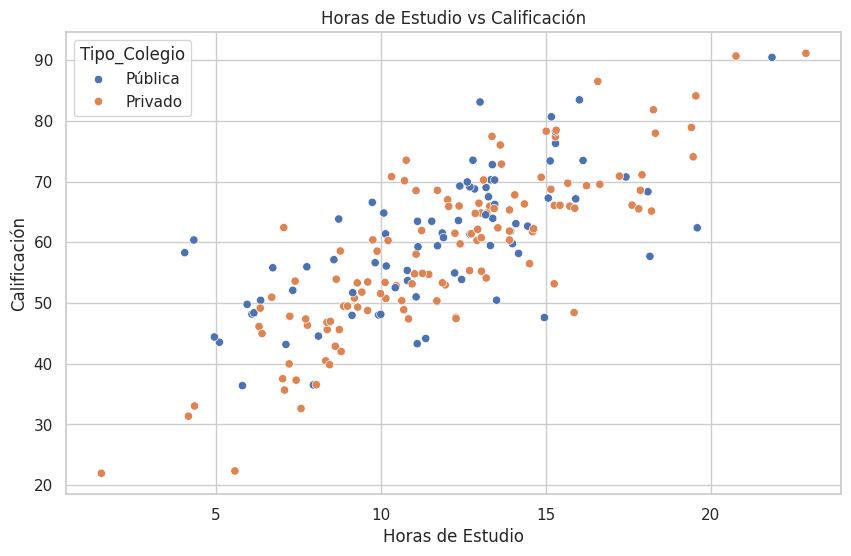

In [9]:
#Gráfico multivariante de dispersión

sns.scatterplot(data=df,x='Horas_Estudio',y='Calificacion',hue='Tipo_Colegio')
plt.title('Horas de Estudio vs Calificación')
plt.xlabel('Horas de Estudio')
plt.ylabel('Calificación')
plt.show

<function matplotlib.pyplot.show(close=None, block=None)>

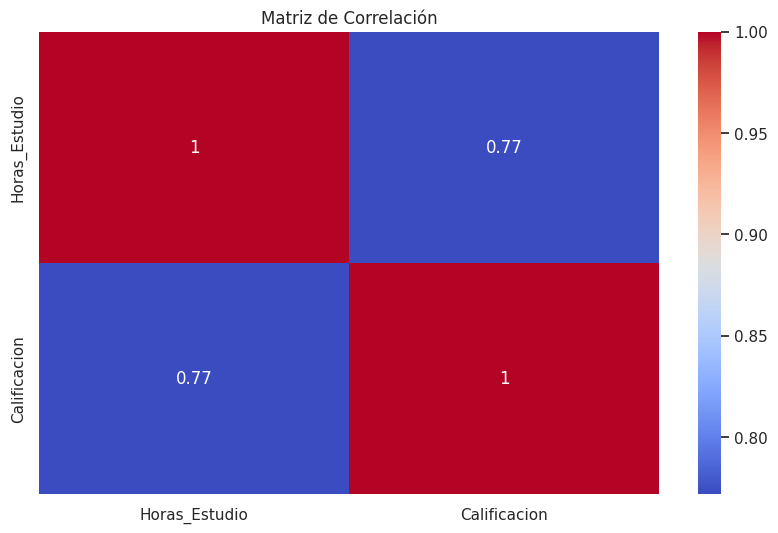

In [10]:
#Heatmap: Es la mejor forma y la recomendada
columnas_numericas=df.select_dtypes(include=[np.number])
matriz_correlacion=columnas_numericas.corr()

sns.heatmap(matriz_correlacion,annot=True,cmap='coolwarm')
plt.title('Matriz de Correlación')
plt.show

# 3. Gráficos de Pares (2 en 2)

El Pairplot genera automáticamente gráficos de dispersión para cada combinación de variables numéricas y diagramas de distribución en la diagonal, segmentadas opcionalmente por una variable categórica.

<function matplotlib.pyplot.show(close=None, block=None)>

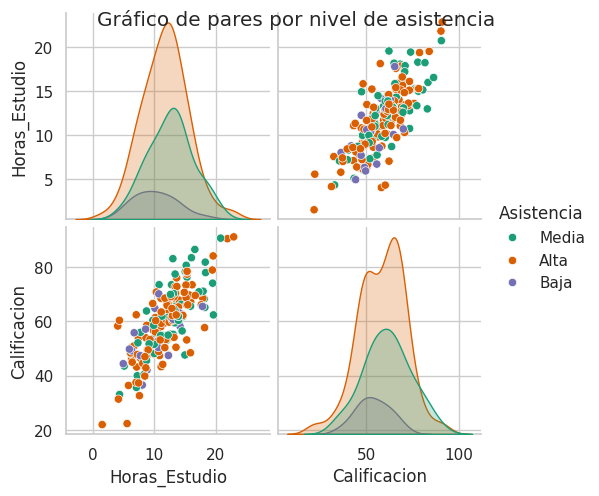

In [11]:
sns.pairplot(df,hue='Asistencia',palette='Dark2')
plt.suptitle('Gráfico de pares por nivel de asistencia')
plt.show